<a href="https://colab.research.google.com/github/LohiaYash/StockPrice/blob/main/StockPrice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [2]:
start = '2016-10-22'
end = '2026-10-22'
stock='GOOG'
data = yf.download(stock,start,end)

/tmp/ipykernel_1235/759487287.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(stock,start,end)
[*********************100%***********************]  1 of 1 completed


In [3]:
data

Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2016-10-24,40.274040,40.376569,39.863432,39.867392,33950000
2016-10-25,40.004593,40.450866,39.879281,40.450866,31528000
2016-10-26,39.578621,39.970410,39.442414,39.938713,32954000
2016-10-27,39.394371,39.797550,39.203676,39.674218,54984000
2016-10-28,39.395367,40.391928,39.307201,40.038276,85398000
...,...,...,...,...,...
2026-10-15,344.910004,348.398010,336.820007,340.529999,16425700
2026-10-16,336.910004,346.600006,335.500000,344.299988,17040300


In [4]:
data.reset_index(inplace=True)

In [5]:
data


Price,Date,Close,High,Low,Open,Volume
Ticker,,GOOG,GOOG,GOOG,GOOG,GOOG
0,2016-10-24,40.274040,40.376569,39.863432,39.867392,33950000
1,2016-10-25,40.004593,40.450866,39.879281,40.450866,31528000
2,2016-10-26,39.578621,39.970410,39.442414,39.938713,32954000
3,2016-10-27,39.394371,39.797550,39.203676,39.674218,54984000
4,2016-10-28,39.395367,40.391928,39.307201,40.038276,85398000
...,...,...,...,...,...,...
2507,2026-10-15,344.910004,348.398010,336.820007,340.529999,16425700
2508,2026-10-16,336.910004,346.600006,335.500000,344.299988,17040300
2509,2026-10-19,340.160004,342.519989,338.251007,340.125000,12720600


In [6]:
ma_100_days = data.Close.rolling(100).mean()

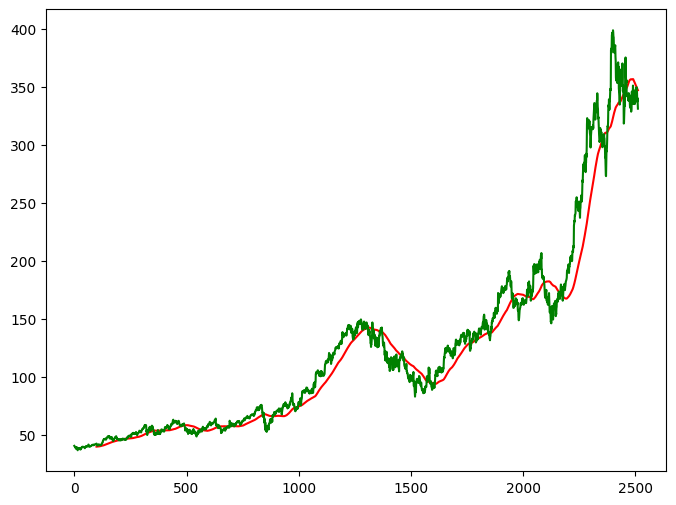

In [7]:
plt.figure(figsize=(8,6))
plt.plot(ma_100_days, 'r')
plt.plot(data.Close, 'g')
plt.show()

In [8]:
ma_200_days = data.Close.rolling(200).mean()

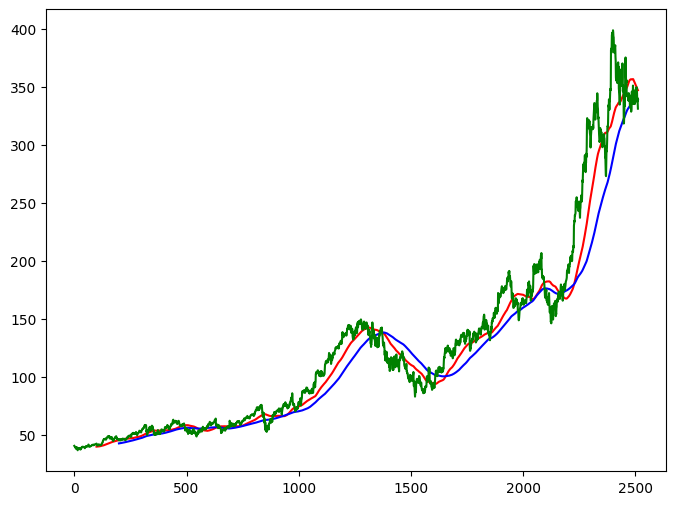

In [9]:
plt.figure(figsize=(8,6))
plt.plot(ma_100_days, 'r')
plt.plot(ma_200_days, 'b')
plt.plot(data.Close, 'g')
plt.show()

In [10]:
data.dropna(inplace=True)

In [11]:
data_train = pd.DataFrame(data.Close[0 : int(len(data)*0.8)])
data_test= pd.DataFrame(data.Close[int(len(data)*0.8): len(data)])

In [12]:
data_train.shape[0]

2009

In [13]:
data_test.shape[0]

503

In [14]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [15]:
data_train_scale = scaler.fit_transform(data_train)

In [16]:
x=[]
y=[]

for i in range(100, data_train_scale.shape[0]):
  x.append(data_train_scale[i-100:i])
  y.append(data_train_scale[i,0])

In [17]:
x, y = np.array(x), np.array(y)

In [18]:
from keras.layers import Dense, Dropout, LSTM
from keras.models import Sequential

In [19]:
model = Sequential()
model.add(LSTM(units = 50, activation = 'relu', return_sequences= True, input_shape = ((x.shape[1],1))))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation= 'relu', return_sequences = True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation= 'relu', return_sequences = True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation= 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units=1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(x,y, epochs = 50, batch_size =32, verbose =1)

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 311ms/step - loss: 0.0346
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 20s 328ms/step - loss: 0.0059
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 283ms/step - loss: 0.0060
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 20s 283ms/step - loss: 0.0051
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 313ms/step - loss: 0.0052
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 282ms/step - loss: 0.0050
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 287ms/step - loss: 0.0045
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 20s 282ms/step - loss: 0.0047
Epoch 9/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 300ms/step - loss: 0.0043
Epoch 10/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 283ms/step - loss: 0.0041
Epoch 11/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 281ms/step - loss: 0.0036
Epoch 12/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 291ms/step - loss: 0.0041
Epoch 13/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 283ms/step - loss: 0.0040
Epoch 14/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 283ms/step - loss: 0.0039
Epoch 15/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 536,285 (2.05 MB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 357,524 (1.36 MB)

In [22]:
pas_100_days = data_train.tail(100)

In [23]:
data_test = pd.concat([pas_100_days, data_test], ignore_index=True)

In [24]:
data_test

Ticker,GOOG
0,176.349670
1,175.735489
2,171.931534
3,172.327774
4,172.783478
...,...
598,344.910004
599,336.910004
600,340.160004
601,336.399994


In [40]:
data_test_scale = scaler.transform(data_test)

In [28]:
x=[]
y=[]

for i in range(100, data_test_scale.shape[0]):
  x.append(data_test_scale[i-100:i])
  y.append(data_test_scale[i,0])

x, y = np.array(x), np.array(y)

In [31]:
y_predict = model.predict(x)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step


In [34]:
scale = 1/scaler.scale_

In [35]:
y_predict = y_predict*scale

In [36]:
y = y*scale

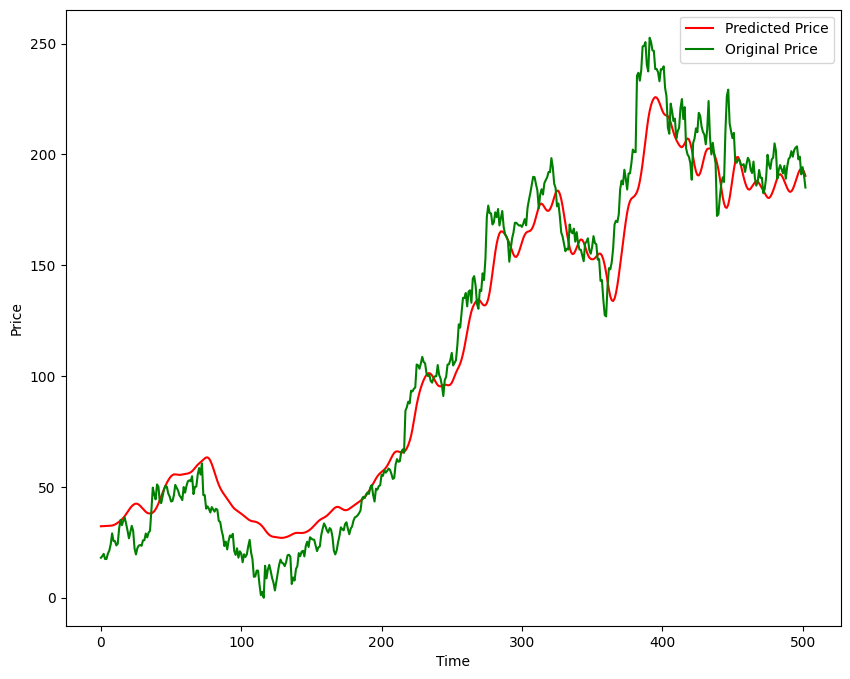

In [38]:
plt.figure(figsize=(10,8))
plt.plot(y_predict, 'r', label = 'Predicted Price')
plt.plot(y, 'g', label = 'Original Price')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

In [39]:
model.save('Stock Prediction Model.keras')

In [41]:
import joblib

model.save('Stock_Prediction_Model.keras')
joblib.dump(scaler, 'scaler.save')

['scaler.save']

In [42]:
from google.colab import files

files.download('Stock_Prediction_Model.keras')
files.download('scaler.save')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>